<a href="https://colab.research.google.com/github/OlatokeJumai/AML_CFT-Compliance/blob/main/Masters_Dissertation_AML_Compliance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Run this cell first. It installs everything the prototype needs.

import subprocess
subprocess.run(["pip", "install", "kaggle", "xgboost", "shap", "lime",
                "imbalanced-learn", "scikit-learn", "pandas", "numpy",
                "matplotlib", "seaborn", "--quiet"])

import os
import json

In [ ]:
# Paste your Kaggle username and fresh token here
KAGGLE_USERNAME = "jumai123"
KAGGLE_TOKEN = "KGAT_3b052ced2c7768acd0f0f88d3c7a79ea"  # Replace with your fresh token


In [ ]:
# This creates the kaggle.json file Colab needs
os.makedirs("/root/.config/kaggle", exist_ok=True)
kaggle_config = {"username": KAGGLE_USERNAME, "key": KAGGLE_TOKEN}
with open("/root/.config/kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_config, f)
os.chmod("/root/.config/kaggle/kaggle.json", 0o600)
print("Kaggle credentials configured successfully.")


Kaggle credentials configured successfully.


In [ ]:

# ============================================================
# SECTION 1 — DATA LOADING (Chapter 4.2)
# Download PaySim dataset directly from Kaggle
# ============================================================

import subprocess
result = subprocess.run(
    ["kaggle", "datasets", "download", "-d",
     "ealaxi/paysim1", "--unzip", "-p", "/content/paysim"],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

import pandas as pd
import numpy as np

df = pd.read_csv("/content/paysim/PS_20174392719_1491204439457_log.csv")
print(f"Dataset loaded successfully.")
print(f"Total transactions: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"\nDataset preview:")
print(df.head())
print(f"\nFraud distribution:")
print(df['isFraud'].value_counts())
print(f"\nFraud rate: {df['isFraud'].mean()*100:.4f}%")

Dataset URL: https://www.kaggle.com/datasets/ealaxi/paysim1
License(s): CC-BY-SA-4.0



  0%|          | 0.00/178M [00:00<?, ?B/s]
  5%|▍         | 8.00M/178M [00:00<00:02, 83.4MB/s]
  9%|▉         | 16.0M/178M [00:00<00:02, 70.9MB/s]
 24%|██▎       | 42.0M/178M [00:00<00:00, 153MB/s] 
 33%|███▎      | 58.0M/178M [00:00<00:00, 149MB/s]
 51%|█████     | 91.0M/178M [00:00<00:00, 174MB/s]
 64%|██████▎   | 113M/178M [00:00<00:00, 187MB/s] 
 74%|███████▎  | 131M/178M [00:00<00:00, 159MB/s]
 83%|████████▎ | 147M/178M [00:00<00:00, 160MB/s]
 92%|█████████▏| 163M/178M [00:01<00:00, 136MB/s]
100%|██████████| 178M/178M [00:01<00:00, 152MB/s]

Dataset loaded successfully.
Total transactions: 6,362,620
Total columns: 11

Dataset preview:
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C130548614

In [ ]:

# ============================================================
# SECTION 2 — DATA PREPARATION (Chapter 4.4)
# Clean, engineer features, handle class imbalance
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [ ]:

# --- 2a. Exploratory Data Analysis ---
print("=== TRANSACTION TYPE DISTRIBUTION ===")
print(df['type'].value_counts())

print("\n=== FRAUD BY TRANSACTION TYPE ===")
print(df.groupby('type')['isFraud'].sum())

=== TRANSACTION TYPE DISTRIBUTION ===
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

=== FRAUD BY TRANSACTION TYPE ===
type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64


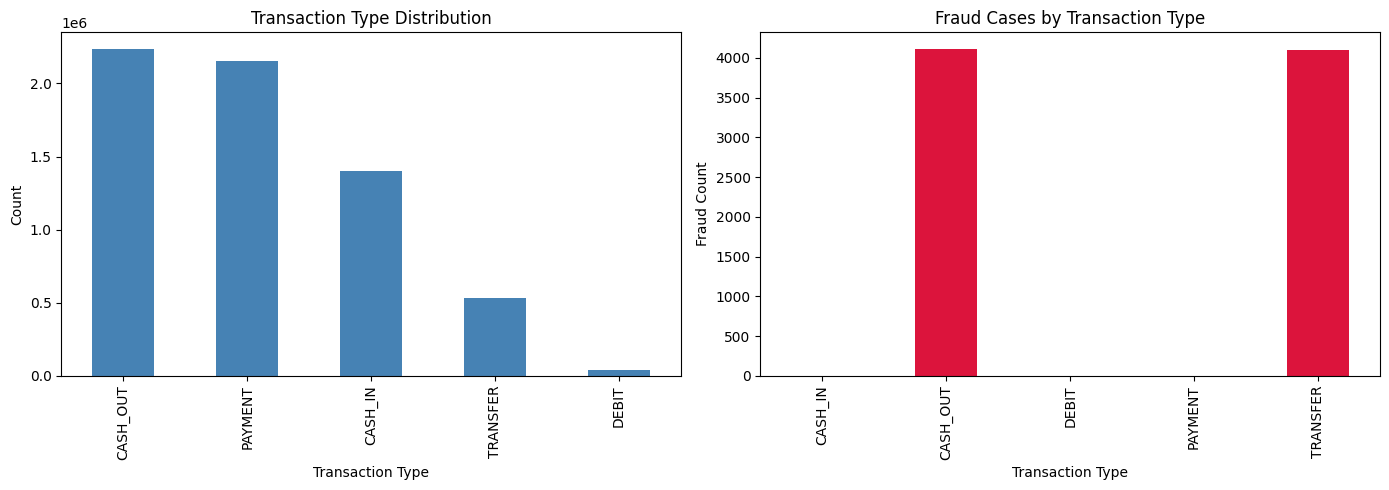

Figure saved: figure_transaction_distribution.png


In [ ]:

# Visualise fraud by transaction type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['type'].value_counts().plot(kind='bar', ax=axes[0],
    color='steelblue', title='Transaction Type Distribution')
axes[0].set_xlabel('Transaction Type')
axes[0].set_ylabel('Count')
df.groupby('type')['isFraud'].sum().plot(kind='bar', ax=axes[1],
    color='crimson', title='Fraud Cases by Transaction Type')
axes[1].set_xlabel('Transaction Type')
axes[1].set_ylabel('Fraud Count')
plt.tight_layout()
plt.savefig('/content/figure_transaction_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_transaction_distribution.png")

In [ ]:

# --- 2b. Feature Engineering ---
# Drop columns not useful for modelling
df = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'])

In [ ]:

# Engineer new features that capture fraud patterns
df['balance_diff_orig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['balance_diff_dest'] = df['newbalanceDest'] - df['oldbalanceDest']
df['orig_balance_zero'] = (df['newbalanceOrig'] == 0).astype(int)
df['amount_to_balance_ratio'] = np.where(
    df['oldbalanceOrg'] > 0,
    df['amount'] / df['oldbalanceOrg'], 0
)


In [ ]:

# One-hot encode transaction type
df = pd.get_dummies(df, columns=['type'], drop_first=False)

print("\n=== ENGINEERED FEATURES ===")
print(df.columns.tolist())
print(f"\nDataset shape after feature engineering: {df.shape}")


=== ENGINEERED FEATURES ===
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'balance_diff_orig', 'balance_diff_dest', 'orig_balance_zero', 'amount_to_balance_ratio', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']

Dataset shape after feature engineering: (6362620, 16)


In [ ]:

# --- 2c. Train/Test Split ---
X = df.drop(columns=['isFraud'])
y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining set size: {len(X_train):,}")
print(f"Test set size: {len(X_test):,}")
print(f"Fraud cases in training set: {y_train.sum():,}")
print(f"Fraud cases in test set: {y_test.sum():,}")


Training set size: 5,090,096
Test set size: 1,272,524
Fraud cases in training set: 6,570
Fraud cases in test set: 1,643


In [ ]:
# --- 2d. SMOTE Balancing ---
print("\nApplying SMOTE to balance training data...")
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
print(f"Training set after SMOTE: {len(X_train_bal):,} transactions")
print(f"Fraud cases after SMOTE: {y_train_bal.sum():,}")
print(f"Class balance after SMOTE: {y_train_bal.mean()*100:.1f}% fraud")


Applying SMOTE to balance training data...
Training set after SMOTE: 10,167,052 transactions
Fraud cases after SMOTE: 5,083,526
Class balance after SMOTE: 50.0% fraud


In [ ]:

# ============================================================
# SECTION 3 — LAYER 1: XGBOOST DETECTION MODEL (Chapter 4.5)
# Train the fraud detection classifier
# ============================================================

import xgboost as xgb
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, precision_score,
                              recall_score, f1_score, accuracy_score)

print("=== TRAINING XGBOOST MODEL ===")
model = xgb.XGBClassifier(
    max_depth=6,
    learning_rate=0.1,
    n_estimators=200,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    use_label_encoder=False,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train_bal, y_train_bal,
    eval_set=[(X_test, y_test)],
    verbose=50
)
print("\nModel training complete.")

=== TRAINING XGBOOST MODEL ===


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:08:16] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[0]	validation_0-auc:0.97764
[50]	validation_0-auc:0.99971
[100]	validation_0-auc:0.99972
[150]	validation_0-auc:0.99956
[199]	validation_0-auc:0.99944

Model training complete.


In [ ]:

# --- Evaluate model ---
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
auc_roc   = roc_auc_score(y_test, y_pred_proba)

print("\n=== MODEL PERFORMANCE RESULTS (Table 4.1) ===")
print(f"Accuracy:               {accuracy*100:.2f}%")
print(f"Precision (fraud):      {precision*100:.2f}%")
print(f"Recall (fraud):         {recall*100:.2f}%")
print(f"F1-Score (fraud):       {f1*100:.2f}%")
print(f"AUC-ROC:                {auc_roc:.4f}")

print("\n=== FULL CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred,
      target_names=['Legitimate', 'Fraudulent']))


=== MODEL PERFORMANCE RESULTS (Table 4.1) ===
Accuracy:               99.92%
Precision (fraud):      62.55%
Recall (fraud):         99.82%
F1-Score (fraud):       76.91%
AUC-ROC:                0.9994

=== FULL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00   1270881
  Fraudulent       0.63      1.00      0.77      1643

    accuracy                           1.00   1272524
   macro avg       0.81      1.00      0.88   1272524
weighted avg       1.00      1.00      1.00   1272524



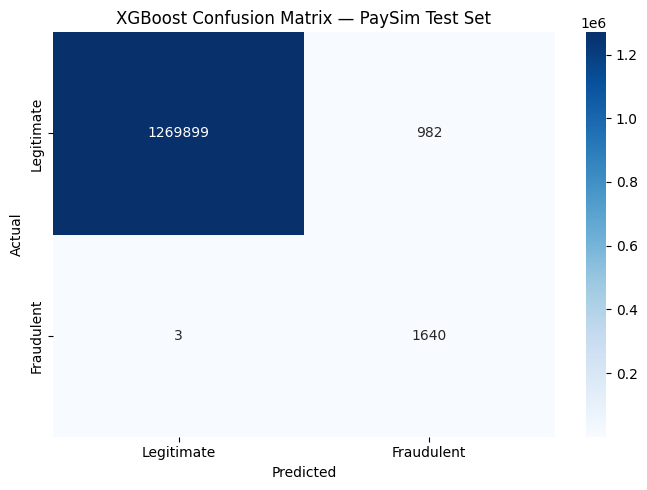

Figure saved: figure_confusion_matrix.png


In [ ]:

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Fraudulent'],
            yticklabels=['Legitimate', 'Fraudulent'])
ax.set_title('XGBoost Confusion Matrix — PaySim Test Set')
ax.set_ylabel('Actual')
ax.set_xlabel('Predicted')
plt.tight_layout()
plt.savefig('/content/figure_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_confusion_matrix.png")

In [ ]:
 #Store results for use in later sections
model_results = {
    "accuracy": round(accuracy * 100, 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1": round(f1 * 100, 2),
    "auc_roc": round(auc_roc, 4)
}
print("\nResults stored. Ready for explainability layer.")


Results stored. Ready for explainability layer.


In [ ]:

# ============================================================
# SECTION 4 — LAYER 2: SHAP EXPLAINABILITY (Chapter 4.6)
# Global feature importance and per-alert local explanations
# ============================================================

import shap

print("=== COMPUTING SHAP VALUES ===")
print("This may take a few minutes on the full test set...")

=== COMPUTING SHAP VALUES ===
This may take a few minutes on the full test set...


In [ ]:

# Use a sample for speed — 2000 transactions is sufficient for SHAP
X_test_sample = X_test.sample(n=2000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_sample)

print("SHAP values computed successfully.")

SHAP values computed successfully.


In [ ]:

# --- Global SHAP feature importance (Table 4.2) ---
mean_shap = pd.DataFrame({
    'Feature': X_test_sample.columns,
    'Mean_SHAP': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean_SHAP', ascending=False)

print("\n=== GLOBAL SHAP FEATURE IMPORTANCE (Table 4.2) ===")
print(mean_shap.to_string(index=False))


=== GLOBAL SHAP FEATURE IMPORTANCE (Table 4.2) ===
                Feature  Mean_SHAP
amount_to_balance_ratio   6.586160
           type_PAYMENT   4.007544
      balance_diff_orig   2.111769
                 amount   1.745855
      orig_balance_zero   1.665975
         oldbalanceDest   1.317631
      balance_diff_dest   1.149594
          type_CASH_OUT   1.080935
         newbalanceOrig   1.079957
           type_CASH_IN   0.905861
          oldbalanceOrg   0.804140
                   step   0.800844
         newbalanceDest   0.676420
          type_TRANSFER   0.474686
             type_DEBIT   0.042501


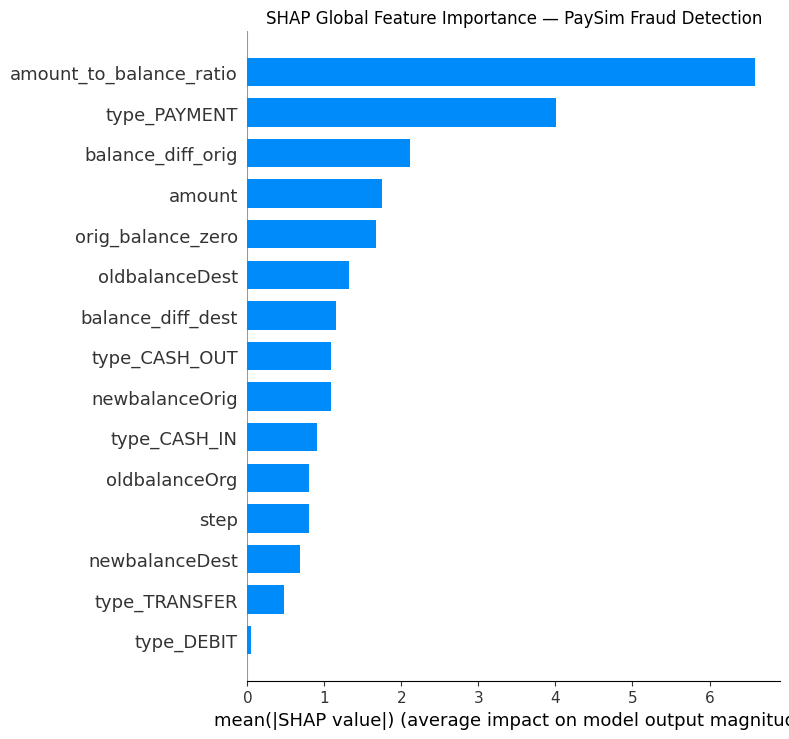

Figure saved: figure_shap_global.png


In [ ]:

# SHAP summary plot
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test_sample,
                  plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance — PaySim Fraud Detection")
plt.tight_layout()
plt.savefig('/content/figure_shap_global.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_shap_global.png")

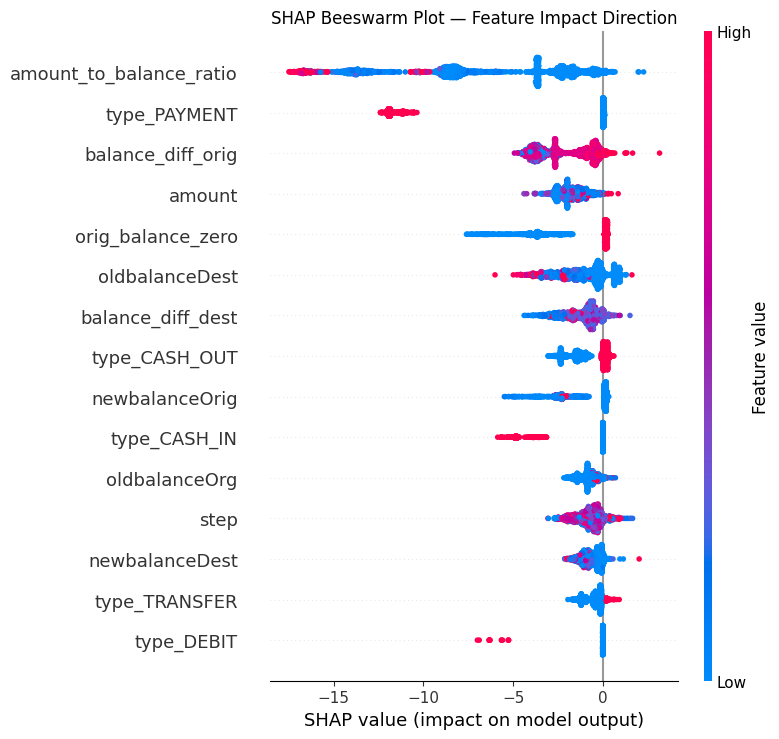

Figure saved: figure_shap_beeswarm.png


In [ ]:
# SHAP beeswarm plot (shows direction of impact)
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("SHAP Beeswarm Plot — Feature Impact Direction")
plt.tight_layout()
plt.savefig('/content/figure_shap_beeswarm.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_shap_beeswarm.png")

In [ ]:
# ============================================================
# SECTION 5 — LAYER 2 (cont.): LIME LOCAL EXPLANATION
# Per-transaction plain English explanation
# ============================================================

from lime.lime_tabular import LimeTabularExplainer

print("=== SETTING UP LIME EXPLAINER ===")
lime_explainer = LimeTabularExplainer(
    training_data=X_train_bal.values,
    feature_names=X_train_bal.columns.tolist(),
    class_names=['Legitimate', 'Fraudulent'],
    mode='classification',
    random_state=42
)

=== SETTING UP LIME EXPLAINER ===


In [ ]:
# Find a confirmed fraud case from the test set
fraud_indices = X_test[y_test == 1].index
sample_fraud_idx = fraud_indices[0]
sample_transaction = X_test.loc[sample_fraud_idx].values

print(f"\nSample fraudulent transaction selected: index {sample_fraud_idx}")
print("\n=== TRANSACTION DETAILS ===")
for col, val in zip(X_test.columns, sample_transaction):
    print(f"  {col}: {val}")



Sample fraudulent transaction selected: index 6202693

=== TRANSACTION DETAILS ===
  step: 583
  amount: 759701.03
  oldbalanceOrg: 759701.03
  newbalanceOrig: 0.0
  oldbalanceDest: 1076095.67
  newbalanceDest: 1835796.71
  balance_diff_orig: 759701.03
  balance_diff_dest: 759701.04
  orig_balance_zero: 1
  amount_to_balance_ratio: 1.0
  type_CASH_IN: False
  type_CASH_OUT: True
  type_DEBIT: False
  type_PAYMENT: False
  type_TRANSFER: False


In [ ]:
# Generate LIME explanation
print("\nGenerating LIME explanation...")
lime_exp = lime_explainer.explain_instance(
    data_row=sample_transaction,
    predict_fn=model.predict_proba,
    num_features=8,
    num_samples=1000
)

print("\n=== LIME LOCAL EXPLANATION (Table 4.3) ===")
print(f"Fraud probability: {model.predict_proba([sample_transaction])[0][1]*100:.2f}%")
print("\nFeature contributions:")
for feat, weight in lime_exp.as_list():
    direction = "TOWARDS FRAUD" if weight > 0 else "AWAY FROM FRAUD"
    print(f"  {feat}: {weight:.4f} ({direction})")



Generating LIME explanation...

=== LIME LOCAL EXPLANATION (Table 4.3) ===
Fraud probability: 100.00%

Feature contributions:
  amount > 547192.74: 0.3044 (TOWARDS FRAUD)
  balance_diff_orig > 442586.83: 0.2138 (TOWARDS FRAUD)
  newbalanceOrig <= 0.00: 0.1949 (TOWARDS FRAUD)
  type_PAYMENT <= 0.00: 0.1925 (TOWARDS FRAUD)
  type_CASH_IN <= 0.00: 0.1382 (TOWARDS FRAUD)
  0.00 < type_CASH_OUT <= 1.00: 0.1234 (TOWARDS FRAUD)
  oldbalanceDest > 509196.10: -0.1026 (AWAY FROM FRAUD)
  type_TRANSFER <= 0.00: -0.0927 (AWAY FROM FRAUD)


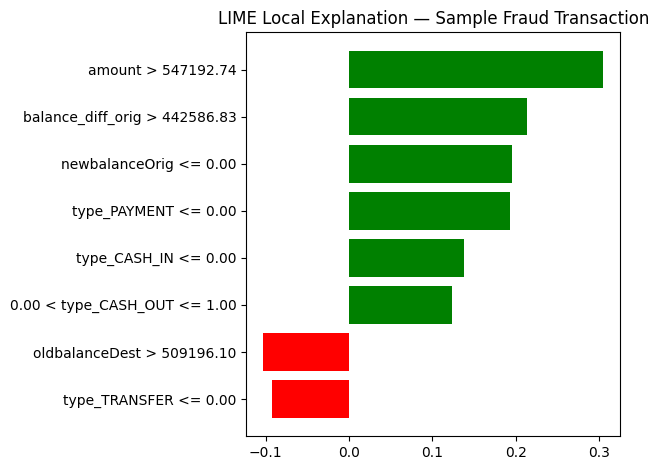

Figure saved: figure_lime_explanation.png


In [ ]:
# Save LIME explanation plot
fig = lime_exp.as_pyplot_figure()
plt.title("LIME Local Explanation — Sample Fraud Transaction")
plt.tight_layout()
plt.savefig('/content/figure_lime_explanation.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_lime_explanation.png")

In [ ]:
# --- LIME Stability Test ---
print("\n=== LIME STABILITY TEST ===")
print("Running LIME 10 times on same transaction to measure consistency...")
from scipy.stats import kendalltau

all_rankings = []
for i in range(10):
    exp = lime_explainer.explain_instance(
        data_row=sample_transaction,
        predict_fn=model.predict_proba,
        num_features=8,
        num_samples=1000
    )
    features_ranked = [f[0] for f in sorted(
        exp.as_list(), key=lambda x: abs(x[1]), reverse=True)]
    all_rankings.append(features_ranked)


=== LIME STABILITY TEST ===
Running LIME 10 times on same transaction to measure consistency...


In [ ]:
# Compute pairwise Kendall tau concordance
concordance_scores = []
for i in range(len(all_rankings)):
    for j in range(i+1, len(all_rankings)):
        common = list(set(all_rankings[i]) & set(all_rankings[j]))
        if len(common) > 1:
            rank_i = [all_rankings[i].index(f) for f in common]
            rank_j = [all_rankings[j].index(f) for f in common]
            tau, _ = kendalltau(rank_i, rank_j)
            concordance_scores.append(tau)

mean_concordance = np.mean(concordance_scores)
print(f"Mean Kendall Tau concordance across 10 runs: {mean_concordance:.4f}")
print(f"Interpretation: {'Strong' if mean_concordance > 0.7 else 'Moderate'} stability")

Mean Kendall Tau concordance across 10 runs: 0.7217
Interpretation: Strong stability


In [ ]:
# ============================================================
# SECTION 6 — LAYER 3: KRR FATF RULE ENGINE (Chapter 4.7)
# Symbolic reasoning — typology classification
# ============================================================

print("=== KRR FATF TYPOLOGY RULE ENGINE ===")

def krr_rule_engine(transaction_features, feature_names, account_history=None):
    """
    KRR Rule Engine — encodes FATF money laundering typologies as
    IF-THEN rules and classifies flagged transactions accordingly.

    Parameters:
        transaction_features: array of feature values
        feature_names: list of feature column names
        account_history: optional dict with historical account stats

    Returns:
        dict with typology classification and plain-English justification
    """
    feat = dict(zip(feature_names, transaction_features))

    conditions_met = []
    typology = None
    justification = []
    fatf_reference = "FATF (2021) Opportunities and Challenges of New Technologies for AML/CFT"
    cbn_reference  = "CBN AML/CFT Baseline Standards 2026 — Circular BSD/DIR/PUB/LAB/019/002"

=== KRR FATF TYPOLOGY RULE ENGINE ===


In [ ]:
# ============================================================
# SECTION 6 — LAYER 3: KRR FATF RULE ENGINE (Chapter 4.7)
# Symbolic reasoning — typology classification
# ============================================================

print("=== KRR FATF TYPOLOGY RULE ENGINE ===")

def krr_rule_engine(transaction_features, feature_names, account_history=None):
    feat = dict(zip(feature_names, transaction_features))

    conditions_met = []
    typology = None
    justification = []
    fatf_reference = "FATF (2021) Opportunities and Challenges of New Technologies for AML/CFT"
    cbn_reference = "CBN AML/CFT Baseline Standards 2026 — Circular BSD/DIR/PUB/LAB/019/002"

    amount = feat.get('amount', 0)
    balance_dropped = feat.get('orig_balance_zero', 0)
    is_cashout = feat.get('type_CASH_OUT', 0)
    is_transfer = feat.get('type_TRANSFER', 0)
    amount_ratio = feat.get('amount_to_balance_ratio', 0)

    REPORTING_THRESHOLD = 1000000

    # RULE SET 1 — SMURFING (STRUCTURING)
    if (amount < REPORTING_THRESHOLD and
        amount > REPORTING_THRESHOLD * 0.7 and
        amount_ratio > 0.8):
        typology = "Smurfing (Structuring)"
        conditions_met = [
            "Transaction amount is just below the regulatory reporting threshold",
            "Amount represents more than 80% of the account balance",
            "Pattern consistent with deliberate sub-threshold structuring"
        ]
        justification = [
            f"Transaction amount ({amount:,.0f}) falls just below the reporting threshold "
            f"({REPORTING_THRESHOLD:,}), suggesting deliberate structuring to avoid detection.",
            "This pattern matches the FATF structuring typology, commonly used to move "
            "criminal proceeds through mobile money channels."
        ]

    # RULE SET 2 — RAPID LAYERING
    elif (is_transfer == 1 and
          balance_dropped == 1 and
          feat.get('oldbalanceOrg', 0) > 0 and
          feat.get('newbalanceDest', 0) > feat.get('oldbalanceDest', 0) * 1.5):
        typology = "Rapid Layering"
        conditions_met = [
            "TRANSFER transaction type — highest risk category",
            "Sending account balance completely drained to zero",
            "Receiving account balance increased significantly",
            "Pattern consistent with funds being moved to obscure origin"
        ]
        justification = [
            "Funds transferred via TRANSFER transaction, completely draining the sending account to zero.",
            "The receiving account shows a significant and unusual balance increase, consistent "
            "with the FATF layering typology associated with terrorism financing networks.",
        ]

    # RULE SET 3 — UNUSUAL ACCOUNT BEHAVIOUR
    elif (amount_ratio > 0.9 or
          (is_cashout == 1 and balance_dropped == 1)):
        typology = "Unusual Account Behaviour (Profile Deviation)"
        conditions_met = [
            "Transaction amount represents more than 90% of account balance",
            "Account balance drained to zero after transaction",
            "Behaviour is inconsistent with typical account usage patterns"
        ]
        justification = [
            "This transaction drains the account balance entirely, which is highly unusual.",
            "This pattern matches the FATF profile deviation typology, associated with "
            "account takeover schemes and money mule accounts."
        ]

    # NO TYPOLOGY MATCHED
    else:
        typology = "Unclassified High-Risk"
        conditions_met = ["No specific FATF typology pattern matched"]
        justification = [
            "The AI model flagged this transaction as suspicious but no specific "
            "FATF typology rule was satisfied.",
            "Transaction requires manual review by a compliance officer."
        ]

    return {
        "typology": typology,
        "conditions_met": conditions_met,
        "justification": justification,
        "fatf_reference": fatf_reference,
        "cbn_reference": cbn_reference,
        "recommended_action": (
            "Escalate for Suspicious Activity Report (SAR) preparation. "
            "Compliance officer review required before filing."
            if typology != "Unclassified High-Risk"
            else "Compliance officer manual review required."
        )
    }


# Test the rule engine on the sample fraud transaction
print("\n=== TESTING RULE ENGINE ON SAMPLE TRANSACTION ===")
krr_result = krr_rule_engine(sample_transaction, X_test.columns.tolist())

print(f"\nTypology Classification: {krr_result['typology']}")
print(f"\nConditions Met:")
for i, cond in enumerate(krr_result['conditions_met'], 1):
    print(f"  {i}. {cond}")
print(f"\nJustification:")
for para in krr_result['justification']:
    print(f"  - {para}")
print(f"\nFATF Reference: {krr_result['fatf_reference']}")
print(f"CBN Reference:  {krr_result['cbn_reference']}")
print(f"Recommended Action: {krr_result['recommended_action']}")

=== KRR FATF TYPOLOGY RULE ENGINE ===

=== TESTING RULE ENGINE ON SAMPLE TRANSACTION ===

Typology Classification: Smurfing (Structuring)

Conditions Met:
  1. Transaction amount is just below the regulatory reporting threshold
  2. Amount represents more than 80% of the account balance
  3. Pattern consistent with deliberate sub-threshold structuring

Justification:
  - Transaction amount (759,701) falls just below the reporting threshold (1,000,000), suggesting deliberate structuring to avoid detection.
  - This pattern matches the FATF structuring typology, commonly used to move criminal proceeds through mobile money channels.

FATF Reference: FATF (2021) Opportunities and Challenges of New Technologies for AML/CFT
CBN Reference:  CBN AML/CFT Baseline Standards 2026 — Circular BSD/DIR/PUB/LAB/019/002
Recommended Action: Escalate for Suspicious Activity Report (SAR) preparation. Compliance officer review required before filing.


In [ ]:
# ============================================================
# SECTION 7 — LAYER 4: GOVERNANCE AUDIT TRAIL (Chapter 4.8)
# Structured JSON record for every flagged transaction
# ============================================================

import datetime
import json

print("=== GENERATING GOVERNANCE AUDIT TRAIL ===")

def generate_audit_record(transaction_id, transaction_features,
                           feature_names, fraud_probability,
                           shap_vals, lime_explanation, krr_output):
    """
    Generates a complete, tamper-evident audit record for a flagged
    transaction, satisfying CBN Baseline Standards 2026 requirements.
    """
    feat = dict(zip(feature_names, transaction_features))

=== GENERATING GOVERNANCE AUDIT TRAIL ===


In [ ]:
# ============================================================
# SECTION 7 — LAYER 4: GOVERNANCE AUDIT TRAIL (Chapter 4.8)
# ============================================================

import datetime
import json
import numpy as np

print("=== GENERATING GOVERNANCE AUDIT TRAIL ===")

def convert_types(obj):
    """Convert numpy types to standard Python types for JSON serialisation."""
    if isinstance(obj, (np.integer,)): return int(obj)
    if isinstance(obj, (np.floating,)): return float(obj)
    if isinstance(obj, (np.ndarray,)): return obj.tolist()
    if isinstance(obj, (np.bool_,)): return bool(obj)
    return obj

def generate_audit_record(transaction_id, transaction_features,
                           feature_names, fraud_probability,
                           shap_vals, lime_explanation, krr_output):

    feat = dict(zip(feature_names, transaction_features))

    # Top 3 SHAP features — convert to native Python floats
    shap_dict = {k: float(v) for k, v in zip(feature_names, shap_vals)}
    top_shap = sorted(shap_dict.items(),
                      key=lambda x: abs(x[1]), reverse=True)[:3]

    # Top LIME features
    top_lime = lime_explanation.as_list()[:3]

    record = {
        "transaction_id": str(transaction_id),
        "timestamp": datetime.datetime.now(datetime.timezone.utc).isoformat(),
        "transaction_type": (
            "TRANSFER" if float(feat.get('type_TRANSFER', 0)) == 1
            else "CASH_OUT" if float(feat.get('type_CASH_OUT', 0)) == 1
            else "OTHER"
        ),
        "amount": float(feat.get('amount', 0)),
        "layer_1_detection": {
            "model": "XGBoost Gradient Boosted Classifier",
            "fraud_probability": round(float(fraud_probability), 4),
            "alert_threshold": 0.50,
            "alert_triggered": bool(float(fraud_probability) >= 0.50)
        },
        "layer_2_explainability": {
            "shap_top_features": [
                {"feature": str(f), "shap_value": round(float(v), 4)}
                for f, v in top_shap
            ],
            "lime_local_explanation": [
                {"feature": str(f), "contribution": round(float(v), 4),
                 "direction": "towards fraud" if float(v) > 0 else "away from fraud"}
                for f, v in top_lime
            ],
            "lime_fraud_probability": round(
                float(lime_explanation.predict_proba[1]), 4)
        },
        "layer_3_krr_reasoning": {
            "fatf_typology": krr_output['typology'],
            "conditions_met": krr_output['conditions_met'],
            "plain_english_justification": krr_output['justification'],
            "fatf_reference": krr_output['fatf_reference'],
            "cbn_reference": krr_output['cbn_reference']
        },
        "layer_4_governance": {
            "recommended_action": krr_output['recommended_action'],
            "human_reviewer_id": None,
            "human_review_decision": None,
            "human_review_timestamp": None,
            "sar_filed": None,
            "audit_status": "PENDING_REVIEW"
        }
    }
    return record


# Get SHAP values for the sample transaction
sample_shap = explainer.shap_values(
    X_test.loc[[sample_fraud_idx]])[0]

# Get feature names
feature_names_list = X_test.columns.tolist()

# Generate the audit record
audit_record = generate_audit_record(
    transaction_id=f"TXN-{sample_fraud_idx}",
    transaction_features=sample_transaction,
    feature_names=feature_names_list,
    fraud_probability=model.predict_proba([sample_transaction])[0][1],
    shap_vals=sample_shap,
    lime_explanation=lime_exp,
    krr_output=krr_result
)

print("\n=== SAMPLE AUDIT RECORD (Section 4.8) ===")
print(json.dumps(audit_record, indent=2))

# Save to file
with open('/content/sample_audit_record.json', 'w') as f:
    json.dump(audit_record, f, indent=2)
print("\nAudit record saved: sample_audit_record.json")

=== GENERATING GOVERNANCE AUDIT TRAIL ===

=== SAMPLE AUDIT RECORD (Section 4.8) ===
{
  "transaction_id": "TXN-6202693",
  "timestamp": "2026-09-27T16:31:41.742144+00:00",
  "transaction_type": "CASH_OUT",
  "amount": 759701.03,
  "layer_1_detection": {
    "model": "XGBoost Gradient Boosted Classifier",
    "fraud_probability": 1.0,
    "alert_threshold": 0.5,
    "alert_triggered": true
  },
  "layer_2_explainability": {
    "shap_top_features": [
      {
        "feature": "balance_diff_orig",
        "shap_value": 3.2172
      },
      {
        "feature": "amount_to_balance_ratio",
        "shap_value": 2.3645
      },
      {
        "feature": "balance_diff_dest",
        "shap_value": -0.6166
      }
    ],
    "lime_local_explanation": [
      {
        "feature": "amount > 547192.74",
        "contribution": 0.3044,
        "direction": "towards fraud"
      },
      {
        "feature": "balance_diff_orig > 442586.83",
        "contribution": 0.2138,
        "direction": "t

In [ ]:
# ============================================================
# SECTION 8 — FAIRNESS EVALUATION (Chapter 4.10)
# Demographic parity and equal opportunity assessment
# ============================================================

print("=== FAIRNESS EVALUATION ===")

=== FAIRNESS EVALUATION ===


In [ ]:
# --- Table 4.4: Alert rate by transaction type ---
print("\n=== TABLE 4.4: ALERT RATE BY TRANSACTION TYPE ===")

type_cols = [c for c in X_test.columns if c.startswith('type_')]
type_results = []

for col in type_cols:
    mask = X_test[col] == 1
    if mask.sum() == 0:
        continue
    total = mask.sum()
    flagged = y_pred[mask.values].sum()
    alert_rate = flagged / total * 100
    type_results.append({
        'Transaction Type': col.replace('type_', '').replace('_', '-'),
        'Total Transactions': f"{total:,}",
        'Transactions Flagged': f"{flagged:,}",
        'Alert Rate (%)': f"{alert_rate:.3f}%"
    })

df_type = pd.DataFrame(type_results)
print(df_type.to_string(index=False))


=== TABLE 4.4: ALERT RATE BY TRANSACTION TYPE ===
Transaction Type Total Transactions Transactions Flagged Alert Rate (%)
         CASH-IN            280,258                    0         0.000%
        CASH-OUT            447,193                1,742         0.390%
           DEBIT              8,285                    0         0.000%
         PAYMENT            430,261                    0         0.000%
        TRANSFER            106,527                  880         0.826%


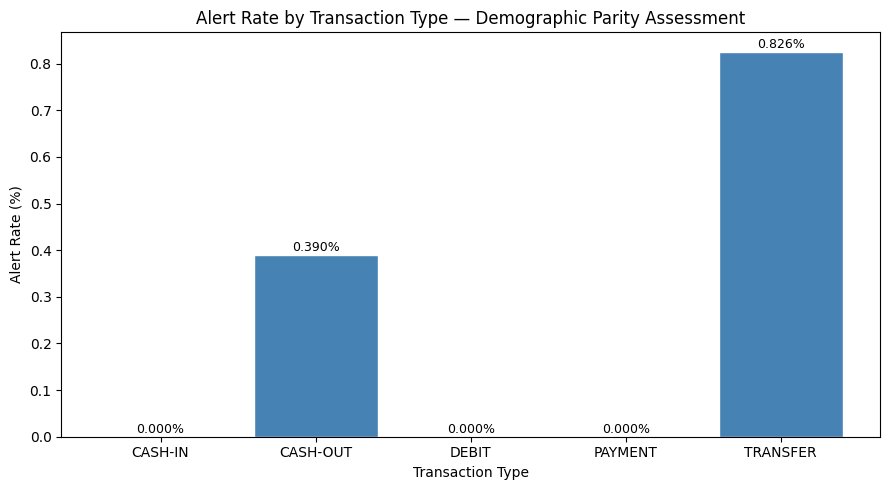

Figure saved: figure_fairness_alert_rate.png


In [ ]:

# Visualise alert rates
fig, ax = plt.subplots(figsize=(9, 5))
alert_vals = [float(r['Alert Rate (%)'].replace('%',''))
              for r in type_results]
type_names = [r['Transaction Type'] for r in type_results]
bars = ax.bar(type_names, alert_vals, color='steelblue', edgecolor='white')
ax.set_title('Alert Rate by Transaction Type — Demographic Parity Assessment')
ax.set_ylabel('Alert Rate (%)')
ax.set_xlabel('Transaction Type')
for bar, val in zip(bars, alert_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{val:.3f}%', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('/content/figure_fairness_alert_rate.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_fairness_alert_rate.png")

In [ ]:

# --- Table 4.5: True positive rate by account balance tier ---
print("\n=== TABLE 4.5: TRUE POSITIVE RATE BY ACCOUNT BALANCE TIER ===")
from sklearn.metrics import recall_score

balance_25 = X_test['oldbalanceOrg'].quantile(0.25)
balance_75 = X_test['oldbalanceOrg'].quantile(0.75)

tiers = {
    'Low (below 25th percentile)':
        X_test['oldbalanceOrg'] <= balance_25,
    'Medium (25th–75th percentile)':
        (X_test['oldbalanceOrg'] > balance_25) &
        (X_test['oldbalanceOrg'] <= balance_75),
    'High (above 75th percentile)':
        X_test['oldbalanceOrg'] > balance_75
}

tier_results = []
for tier_name, mask in tiers.items():
    tier_mask = mask.values
    y_true_tier = y_test.values[tier_mask]
    y_pred_tier = y_pred[tier_mask]
    fraud_in_tier = y_true_tier.sum()
    if fraud_in_tier == 0:
        continue
    tpr = recall_score(y_true_tier, y_pred_tier, zero_division=0)
    fnr = 1 - tpr
    tier_results.append({
        'Account Balance Tier': tier_name,
        'Fraud Cases': f"{fraud_in_tier:,}",
        'True Positive Rate': f"{tpr*100:.2f}%",
        'False Negative Rate': f"{fnr*100:.2f}%"
    })

df_tiers = pd.DataFrame(tier_results)
print(df_tiers.to_string(index=False))


=== TABLE 4.5: TRUE POSITIVE RATE BY ACCOUNT BALANCE TIER ===
         Account Balance Tier Fraud Cases True Positive Rate False Negative Rate
  Low (below 25th percentile)           6             66.67%              33.33%
Medium (25th–75th percentile)         363             99.72%               0.28%
 High (above 75th percentile)       1,274            100.00%               0.00%


In [ ]:
# Disparate impact ratio
tpr_values = [float(r['True Positive Rate'].replace('%',''))
              for r in tier_results]
if len(tpr_values) >= 2:
    disparate_impact = min(tpr_values) / max(tpr_values)
    print(f"\nDisparate Impact Ratio: {disparate_impact:.4f}")
    print(f"Threshold: 0.80 | Status: "
          f"{'PASS — within acceptable range' if disparate_impact >= 0.80 else 'REVIEW REQUIRED'}")


Disparate Impact Ratio: 0.6667
Threshold: 0.80 | Status: REVIEW REQUIRED


In [ ]:

# ============================================================
# SECTION 9 — FULL PIPELINE TEST (All 4 layers together)
# Run a batch of transactions through the complete system
# ============================================================

print("\n=== RUNNING FULL PIPELINE ON BATCH OF FLAGGED TRANSACTIONS ===")


=== RUNNING FULL PIPELINE ON BATCH OF FLAGGED TRANSACTIONS ===


In [ ]:
# Get all fraud predictions from test set
flagged_mask = y_pred == 1
flagged_X = X_test[flagged_mask]
flagged_true = y_test[flagged_mask]

print(f"Total transactions flagged by model: {len(flagged_X):,}")
print(f"Of which genuinely fraudulent: {flagged_true.sum():,}")
print(f"Precision on flagged set: "
      f"{flagged_true.sum()/len(flagged_X)*100:.2f}%")

Total transactions flagged by model: 2,622
Of which genuinely fraudulent: 1,640
Precision on flagged set: 62.55%


In [ ]:

# Run KRR rule engine on first 20 flagged transactions
print("\nKRR Typology Classification on first 20 flagged transactions:")
typology_counts = {}
for idx in flagged_X.index[:20]:
    txn = X_test.loc[idx].values
    result = krr_rule_engine(txn, X_test.columns.tolist())
    t = result['typology']
    typology_counts[t] = typology_counts.get(t, 0) + 1

print("\nTypology distribution in sample:")
for t, count in sorted(typology_counts.items(),
                        key=lambda x: x[1], reverse=True):
    print(f"  {t}: {count} transactions")



KRR Typology Classification on first 20 flagged transactions:

Typology distribution in sample:
  Unusual Account Behaviour (Profile Deviation): 18 transactions
  Smurfing (Structuring): 1 transactions
  Rapid Layering: 1 transactions


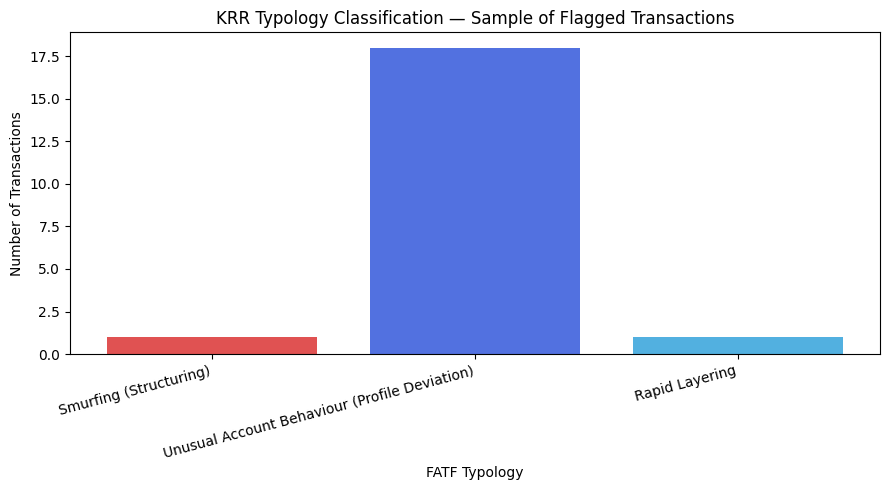

Figure saved: figure_typology_distribution.png


In [ ]:

# Visualise typology distribution
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(list(typology_counts.keys()), list(typology_counts.values()),
       color=['#e05252','#5271e0','#52b0e0','#e0a852'][:len(typology_counts)])
ax.set_title('KRR Typology Classification — Sample of Flagged Transactions')
ax.set_ylabel('Number of Transactions')
ax.set_xlabel('FATF Typology')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.savefig('/content/figure_typology_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: figure_typology_distribution.png")

In [ ]:

# ============================================================
# SECTION 10 — RESULTS SUMMARY
# Print all key numbers for Chapter 4 write-up
# ============================================================

print("\n" + "="*60)
print("COMPLETE RESULTS SUMMARY — COPY INTO CHAPTER 4")
print("="*60)
print(f"\n[Table 4.1] MODEL PERFORMANCE:")
print(f"  Accuracy:          {model_results['accuracy']}%")
print(f"  Precision (fraud): {model_results['precision']}%")
print(f"  Recall (fraud):    {model_results['recall']}%")
print(f"  F1-Score (fraud):  {model_results['f1']}%")
print(f"  AUC-ROC:           {model_results['auc_roc']}")
print(f"\n[Table 4.2] TOP SHAP FEATURES:")
print(mean_shap.head(6).to_string(index=False))
print(f"\n[LIME STABILITY]")
print(f"  Mean Kendall Tau: {mean_concordance:.4f}")
print(f"\n[Table 4.4] ALERT RATES BY TRANSACTION TYPE:")
print(df_type.to_string(index=False))
print(f"\n[Table 4.5] TRUE POSITIVE RATE BY BALANCE TIER:")
print(df_tiers.to_string(index=False))
if len(tpr_values) >= 2:
    print(f"\n[DISPARATE IMPACT RATIO]: {disparate_impact:.4f}")
print("\n" + "="*60)
print("ALL FIGURES SAVED TO /content/ — download from Colab")
print("Files: figure_transaction_distribution.png")
print("       figure_confusion_matrix.png")
print("       figure_shap_global.png")
print("       figure_shap_beeswarm.png")
print("       figure_lime_explanation.png")
print("       figure_fairness_alert_rate.png")
print("       figure_typology_distribution.png")
print("       sample_audit_record.json")
print("="*60)



COMPLETE RESULTS SUMMARY — COPY INTO CHAPTER 4

[Table 4.1] MODEL PERFORMANCE:
  Accuracy:          99.92%
  Precision (fraud): 62.55%
  Recall (fraud):    99.82%
  F1-Score (fraud):  76.91%
  AUC-ROC:           0.9994

[Table 4.2] TOP SHAP FEATURES:
                Feature  Mean_SHAP
amount_to_balance_ratio   6.586160
           type_PAYMENT   4.007544
      balance_diff_orig   2.111769
                 amount   1.745855
      orig_balance_zero   1.665975
         oldbalanceDest   1.317631

[LIME STABILITY]
  Mean Kendall Tau: 0.7217

[Table 4.4] ALERT RATES BY TRANSACTION TYPE:
Transaction Type Total Transactions Transactions Flagged Alert Rate (%)
         CASH-IN            280,258                    0         0.000%
        CASH-OUT            447,193                1,742         0.390%
           DEBIT              8,285                    0         0.000%
         PAYMENT            430,261                    0         0.000%
        TRANSFER            106,527                 